In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import gaussian_kde,mannwhitneyu
warnings.filterwarnings("ignore")
np.random.seed(7)

In [2]:
def violin_with_scatter_latest(dataframe,ax=None,errorbar = "sem", width=0.5,alpha_points=0.5,alpha_violin=0.25,pointsize=20,decimal_places=4,legend_label=None,xticklabel_array=[],manual_colors=False,column_colors=[],mean_color = "k"):
    rows = dataframe.shape[0]
    cols = dataframe.shape[1]
    xticklabels = []
    if ax == None:
        ax = plt.gca() 
    for i in range(cols):
        #get the kernal density estimate for each column to spread the scatter points according to distribution
        data = dataframe.iloc[:,i].dropna()
        data_mean = data.mean(axis=0)
        data_std = data.std(axis=0)
        data_sem = data.sem(axis=0)
        if len(data.unique()) != 1: # this is added to omit calculation of kde for the columns where all the values are same
            kde = gaussian_kde(data)
            density = kde(data)
            density_norm = density/max(density) # normalize the density to range[0,1]
        jitter = np.random.rand(*data.shape) - 0.5 # this is used to add a random displacement in x direction so that points do not overlap
        
        if len(data.unique()) != 1: # this is added to omit calculation of kde for the columns where all the values are same
            xvals = np.ones(data.shape)*i + jitter*width*density_norm
        else:
            xvals = np.ones(data.shape)*i + jitter*width
        #plot scatter points, violin and mean with std
        if manual_colors:
            ax.scatter(xvals,data,alpha=alpha_points,s = pointsize,label=legend_label,color = column_colors[i])
            violin_parts = ax.violinplot(data.values,[i],showmeans=False,showextrema=False,showmedians=False)
            for pc in violin_parts['bodies']:
                pc.set_facecolor(column_colors[i]) 
            
        else:
            ax.scatter(xvals,data,alpha=alpha_points,s = pointsize,label=legend_label)
            ax.violinplot(data.values,[i],showmeans=False,showextrema=False,showmedians=False)
        #ax.errorbar(x = [i],y = data_mean,yerr= data_std,fmt="_",markersize=50,markeredgewidth=2,color="k", capsize=5,elinewidth=2,solid_capstyle='round')
        if errorbar == "std":
            ax.errorbar(x = [i],y = data_mean,yerr= data_std,fmt="_",markersize=50,markeredgewidth=2,color=mean_color, capsize=5,elinewidth=2)
            if len(xticklabel_array) == 0:
                xticklabel = f"{dataframe.columns[i]}\n(n={data.shape[0]})\n{np.round(data_mean,decimal_places)} $\pm$ {np.round(data_std,decimal_places)}"
            elif len(xticklabel_array) != 0:
                xticklabel = f"{xticklabel_array[i]}\n(n={data.shape[0]})\n{np.round(data_mean,decimal_places)} $\pm$ {np.round(data_std,decimal_places)}"
                    
        elif errorbar == "sem":
            ax.errorbar(x = [i],y = data_mean,yerr= data_sem,fmt="_",markersize=50,markeredgewidth=2,color=mean_color, capsize=5,elinewidth=2)
            if len(xticklabel_array) == 0:
                xticklabel = f"{dataframe.columns[i]}\n(n={data.shape[0]})\n{np.round(data_mean,decimal_places)} $\pm$ {np.round(data_sem,decimal_places)}"
            elif len(xticklabel_array) != 0:
                xticklabel = f"{xticklabel_array[i]}\n(n={data.shape[0]})\n{np.round(data_mean,decimal_places)} $\pm$ {np.round(data_sem,decimal_places)}"
        xticklabels.append(xticklabel)
    
    #hide top,right and bottom spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    #set xticks and labels
    ax.set_xticks(np.arange(cols))
    ax.set_xticklabels(xticklabels)
    ax.tick_params(bottom=False,labelbottom=True)
    
    return ax

def plotComparisonViolin(df_NHS60, df_Sucrose, metric, region, save_extension="png", ymin = -0.2, ymax = 1.4):
    '''
    metric: "mean","std","median"
    save_extension: "png","svg"
    '''
    
    fig,ax = plt.subplots(1,1,figsize=(14,5))

    u_during,p_during = mannwhitneyu(df_Sucrose[f"During{metric.capitalize()}"].dropna().values,df_NHS60[f"During{metric.capitalize()}"].dropna().values)
    u_post1,p_post1 = mannwhitneyu(df_Sucrose[f"Post1{metric.capitalize()}"].dropna().values,df_NHS60[f"Post1{metric.capitalize()}"].dropna().values)
    u_post2,p_post2 = mannwhitneyu(df_Sucrose[f"Post2{metric.capitalize()}"].dropna().values,df_NHS60[f"Post2{metric.capitalize()}"].dropna().values)
    u_post3,p_post3 = mannwhitneyu(df_Sucrose[f"Post3{metric.capitalize()}"].dropna().values,df_NHS60[f"Post3{metric.capitalize()}"].dropna().values)
    u_post4,p_post4 = mannwhitneyu(df_Sucrose[f"Post4{metric.capitalize()}"].dropna().values,df_NHS60[f"Post4{metric.capitalize()}"].dropna().values)
    u_post5,p_post5 = mannwhitneyu(df_Sucrose[f"Post5{metric.capitalize()}"].dropna().values,df_NHS60[f"Post5{metric.capitalize()}"].dropna().values)
    
    p_threshold = 0.05
    
    color_p_during = "red" if p_during < p_threshold else "black"
    color_p_post1 = "red" if p_post1 < p_threshold else "black"
    color_p_post2 = "red" if p_post2 < p_threshold else "black"
    color_p_post3 = "red" if p_post3 < p_threshold else "black"
    color_p_post4 = "red" if p_post4 < p_threshold else "black"
    color_p_post5 = "red" if p_post5 < p_threshold else "black"
    
    df_Sucrose.index = [f"Fly {i+1}" for i in range(df_Sucrose.shape[0])]
    df_Sucrose.columns = ['PreSucrose','DuringSucrose','Post1Sucrose','Post2Sucrose','Post3Sucrose','Post4Sucrose','Post5Sucrose']
    
    df_NHS60.index = [f"Fly {i+1}" for i in range(df_NHS60.shape[0])]
    df_NHS60.columns = ['PreNHS','DuringNHS','Post1NHS','Post2NHS','Post3NHS','Post4NHS','Post5NHS']
    
    df_comparison = pd.concat((df_Sucrose,df_NHS60),axis=1)
    col_order = ['PreSucrose','PreNHS','DuringSucrose','DuringNHS','Post1Sucrose','Post1NHS','Post2Sucrose','Post2NHS','Post3Sucrose','Post3NHS','Post4Sucrose','Post4NHS','Post5Sucrose','Post5NHS']
    

    sucrose_color = "blue"
    nhs_color = "red"
    label_color = "k"
    label_y = ymax*0.95
    p_value_y = ymax*0.85
    
    xticklabel_array = ["" for i in range(df_comparison.shape[1])]
    
    violin_with_scatter_latest(df_comparison[col_order],ax=ax,decimal_places=2,errorbar="std",manual_colors=True,column_colors=[sucrose_color,nhs_color,sucrose_color,nhs_color,sucrose_color,nhs_color,sucrose_color,nhs_color,sucrose_color,nhs_color,sucrose_color,nhs_color,sucrose_color,nhs_color,sucrose_color,nhs_color],xticklabel_array=xticklabel_array)
    
    ax.axhline(0,ls="--",color="k",alpha=0.25)
    ax.axvline(1.5,ls="--",color="k",alpha=0.25)
    ax.axvline(3.5,ls="--",color="k",alpha=0.25)
    ax.axvline(5.5,ls="--",color="k",alpha=0.25)
    ax.axvline(7.5,ls="--",color="k",alpha=0.25)
    ax.axvline(9.5,ls="--",color="k",alpha=0.25)
    ax.axvline(11.5,ls="--",color="k",alpha=0.25)
    
    ax.text(0.5,label_y,"Pre-feeding",ha="center",va="center",color = label_color)
    ax.text(2.5,label_y,"During feeding\n(5 min)",ha="center",va="center",color = label_color)
    ax.text(4.5,label_y,"0-5 min\nPost-feeding",ha="center",va="center",color = label_color)
    ax.text(6.5,label_y,"5-10 min\nPost-feeding",ha="center",va="center",color = label_color)
    ax.text(8.5,label_y,"10-15 min\nPost-feeding",ha="center",va="center",color = label_color)
    ax.text(10.5,label_y,"15-20 min\nPost-feeding",ha="center",va="center",color = label_color)
    ax.text(12.5,label_y,"20-25 min\nPost-feeding",ha="center",va="center",color = label_color)
    
    ax.set_xlim(-0.5,13.5)
    ax.set_ylim(ymin,ymax)
    ax.set_ylabel(f"{metric.capitalize()} "+r"$\Delta$F/F")
    
    sucrose_legend_rect = Rectangle((-0.25, ymax*0.7), 0.4, ymax*0.05, linewidth=1, edgecolor=sucrose_color, facecolor=sucrose_color,alpha=0.25)
    nhs_legend_rect = Rectangle((-0.25, ymax*0.6), 0.4, ymax*0.05, linewidth=1, edgecolor=nhs_color, facecolor=nhs_color,alpha=0.25)
    
    ax.text(0.2,ymax*0.71,"Sucrose",color="k")
    ax.text(0.2,ymax*0.61,"Sucrose + NHS",color="k")
    
    ax.add_patch(sucrose_legend_rect)
    ax.add_patch(nhs_legend_rect)
    
    ax.text(2.5,p_value_y,f"p={p_during:.2e}",ha="center",va="center",color = color_p_during)
    ax.text(4.5,p_value_y,f"p={p_post1:.2e}",ha="center",va="center",color = color_p_post1)
    ax.text(6.5,p_value_y,f"p={p_post2:.2e}",ha="center",va="center",color = color_p_post2)
    ax.text(8.5,p_value_y,f"p={p_post3:.2e}",ha="center",va="center",color = color_p_post3)
    ax.text(10.5,p_value_y,f"p={p_post4:.2e}",ha="center",va="center",color = color_p_post4)
    ax.text(12.5,p_value_y,f"p={p_post5:.2e}",ha="center",va="center",color = color_p_post5)
        
    ax.set_title("Genotype: TH(D4) > GCaMP6m \n(Region: " + r"$\gamma$1pedc)")
    
    plt.tight_layout()

    df_comparison[col_order].to_csv(f"../csv_files/Sucrose_vs_NHS_response_{metric}_comparison_violin_data_of_TH_D4_X_GCaMP6m_for_{region}.csv")
    
    plt.savefig(f"../figures/Sucrose_vs_NHS_response_{metric}_comparison_violin_of_TH_D4_X_GCaMP6m_for_{region}.{save_extension}",dpi=600,transparent=True)


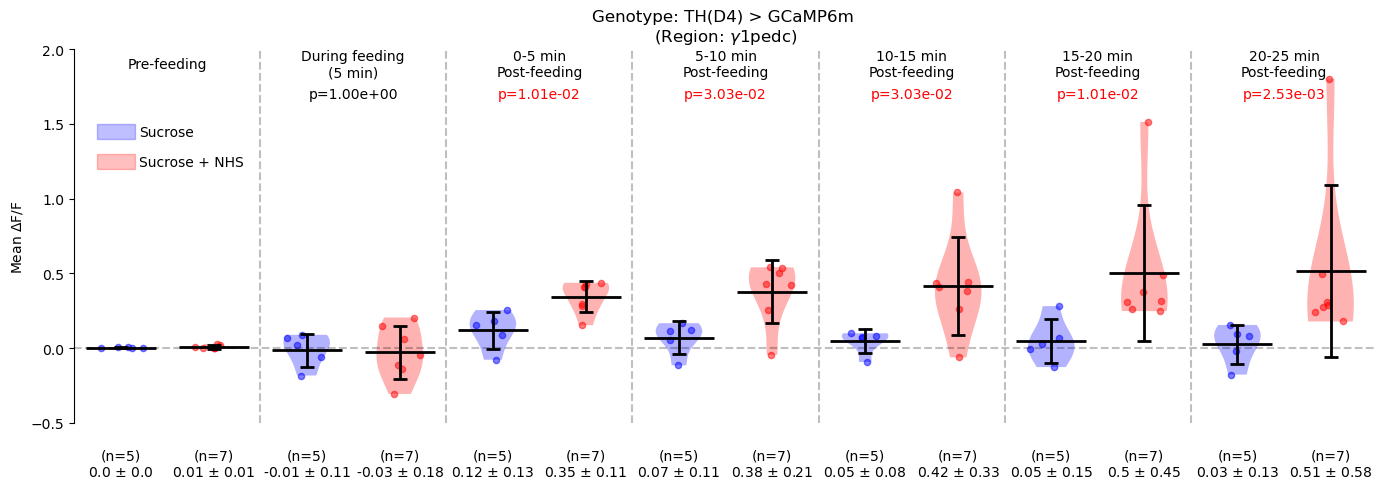

In [3]:
region = "gamma1pedc"

df_data_region_NHS60 = pd.read_csv(f"../csv_files/Brainwise_time_binned_mean_dFF_response_of_{region}_for_NHS60.csv",index_col=0)
df_data_region_Sucrose = pd.read_csv(f"../csv_files/Brainwise_time_binned_mean_dFF_response_of_{region}_for_Sucrose.csv",index_col=0)

mean_cols = ['PreMean','DuringMean','Post1Mean','Post2Mean','Post3Mean','Post4Mean','Post5Mean']

#----------[NHS60]--------------

df_NHS60_mean = df_data_region_NHS60[mean_cols]

#----------[Sucrose]--------------

df_Sucrose_mean = df_data_region_Sucrose[mean_cols]

#----------[Sucrose|NHS60]-----------

df_comparison_mean = pd.concat((df_Sucrose_mean,df_NHS60_mean),axis=0)
    
ymin_mean = -0.5
ymax_mean = 2
ymin_std = -0.1
ymax_std = 0.6
ymin_median = -0.5
ymax_median = 2
    
#---------[Plot violin for mean response]---------------

plotComparisonViolin(df_NHS60 = df_NHS60_mean, df_Sucrose = df_Sucrose_mean, metric = "mean", region = region, save_extension = "svg", ymin = ymin_mean, ymax = ymax_mean)
